In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA

PROJECT = Path("..")
RAW = PROJECT / "data" / "raw"
PROCESSED = PROJECT / "data" / "processed"
OUTPUT = PROJECT / "outputs"
PLOTS = OUTPUT / "visualizations"

for folder in [PROCESSED, OUTPUT, PLOTS]:
    folder.mkdir(parents=True, exist_ok=True)

print("Raw data folder:", RAW.resolve())
print("Files found:", [f.name for f in RAW.glob("*.csv")])

Raw data folder: /home/nineleaps/Downloads/Uber_Eats_Operational_Intelligence/data/raw
Files found: ['customers.csv', 'reviews.csv', 'payments.csv', 'deliveries.csv', 'drivers.csv', 'orders.csv', 'restaurants.csv']


In [ ]:
ORDER_FILE = "orders.csv"
TIMESTAMP_COL = "order_timestamp"
ORDER_ID_COL = "order_id"

file_path = RAW / ORDER_FILE
if not file_path.exists():
    raise FileNotFoundError(
        f"Could not find {file_path}. Check the filenames printed in Section 1 "
        "and update ORDER_FILE."
    )

orders = pd.read_csv(file_path)
print("Dataset shape:", orders.shape)
print("Columns:", orders.columns.tolist())
display(orders.head())

Dataset shape: (3000, 6)
Columns: ['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'order_status']


,order_id,customer_id,restaurant_id,order_timestamp,order_amount,order_status
0,1,258,37,2025-09-17 12:00:00,891.05,Delivered
1,2,180,19,2025-09-27 15:00:00,1037.56,Delivered
2,3,487,33,2025-04-30 07:00:00,1445.94,Delivered
3,4,373,47,2025-02-19 01:00:00,943.74,Delivered
4,5,172,16,2025-07-18 08:00:00,883.27,Delivered


In [3]:
orders[TIMESTAMP_COL] = pd.to_datetime(orders[TIMESTAMP_COL], errors="coerce")

before = len(orders)
orders = orders.dropna(subset=[TIMESTAMP_COL]).copy()
print("Rows removed for invalid timestamps:", before - len(orders))

if ORDER_ID_COL is not None:
    orders = orders.drop_duplicates(subset=[ORDER_ID_COL]).copy()

print("Rows remaining:", len(orders))
print("Date range:", orders[TIMESTAMP_COL].min(), "to", orders[TIMESTAMP_COL].max())
print("Missing timestamps:", orders[TIMESTAMP_COL].isna().sum())

orders.to_csv(PROCESSED / "day5_cleaned_orders.csv", index=False)
display(orders.head())

Rows removed for invalid timestamps: 0
Rows remaining: 3000
Date range: 2025-01-01 02:00:00 to 2025-12-31 22:00:00
Missing timestamps: 0


,order_id,customer_id,restaurant_id,order_timestamp,order_amount,order_status
0,1,258,37,2025-09-17 12:00:00,891.05,Delivered
1,2,180,19,2025-09-27 15:00:00,1037.56,Delivered
2,3,487,33,2025-04-30 07:00:00,1445.94,Delivered
3,4,373,47,2025-02-19 01:00:00,943.74,Delivered
4,5,172,16,2025-07-18 08:00:00,883.27,Delivered


In [4]:
orders["hour"] = orders[TIMESTAMP_COL].dt.floor("h")

hourly = orders.groupby("hour").size().rename("order_count").to_frame()

all_hours = pd.date_range(hourly.index.min(), hourly.index.max(), freq="h")
hourly = hourly.reindex(all_hours, fill_value=0)
hourly.index.name = "timestamp"

hourly.to_csv(OUTPUT / "day5_hourly_demand.csv")
print("Hourly records:", len(hourly))
display(hourly.head())
display(hourly["order_count"].describe())

Hourly records: 8757


,order_count
timestamp,
2025-01-01 02:00:00,1
2025-01-01 03:00:00,0
2025-01-01 04:00:00,0
2025-01-01 05:00:00,0
2025-01-01 06:00:00,1


count    8757.000000
mean        0.342583
std         0.587506
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         4.000000
Name: order_count, dtype: float64

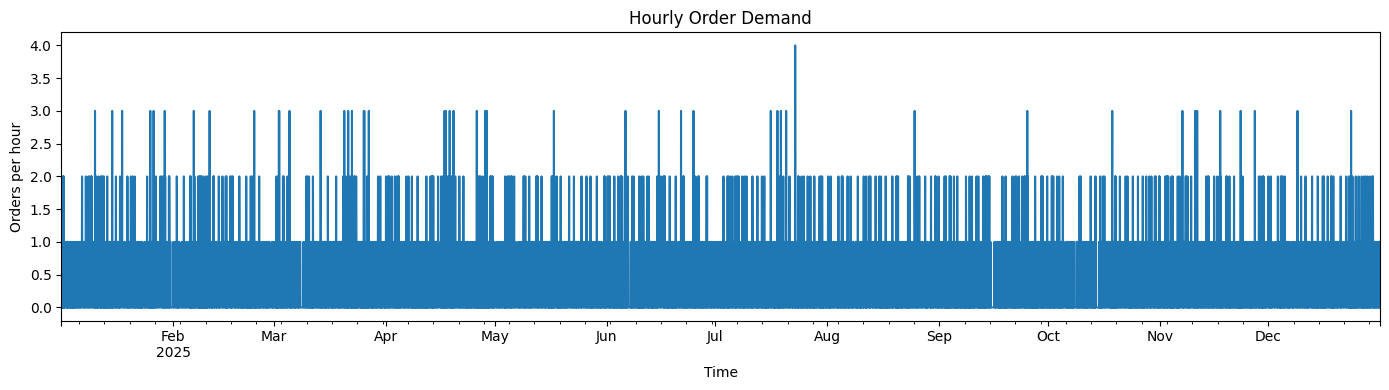

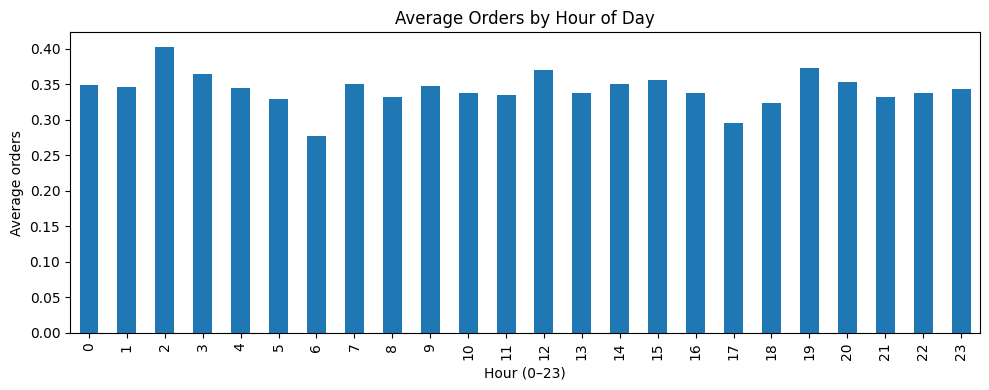

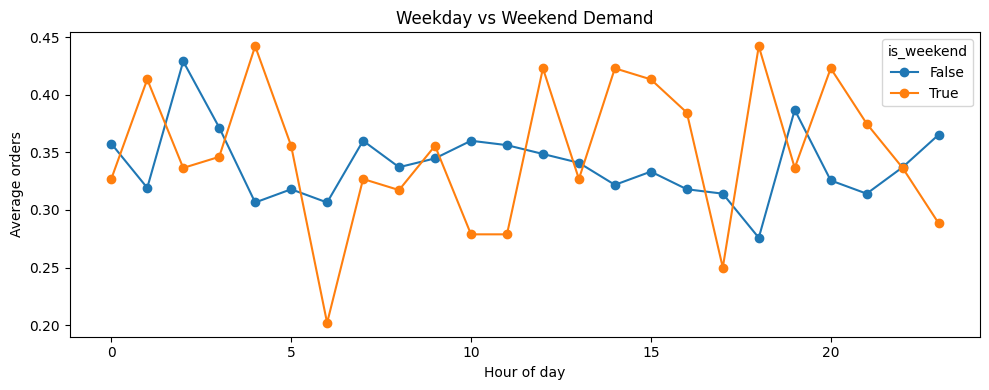

Top 5 peak hours:


hour_of_day
2     0.402740
19    0.372603
12    0.369863
3     0.364384
15    0.356164
Name: order_count, dtype: float64

In [5]:
# Demand over time
hourly["order_count"].plot(figsize=(14, 4), title="Hourly Order Demand")
plt.xlabel("Time")
plt.ylabel("Orders per hour")
plt.tight_layout()
plt.savefig(PLOTS / "day5_hourly_demand.png", dpi=150)
plt.show()

# Average demand by hour of day
hourly["hour_of_day"] = hourly.index.hour
average_by_hour = hourly.groupby("hour_of_day")["order_count"].mean()

average_by_hour.plot(kind="bar", figsize=(10, 4), title="Average Orders by Hour of Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Average orders")
plt.tight_layout()
plt.savefig(PLOTS / "day5_average_by_hour.png", dpi=150)
plt.show()

# Weekday vs weekend
hourly["is_weekend"] = hourly.index.dayofweek >= 5
weekday_weekend = hourly.groupby(
    [hourly.index.hour, "is_weekend"]
)["order_count"].mean().unstack()

weekday_weekend.plot(figsize=(10, 4), marker="o", title="Weekday vs Weekend Demand")
plt.xlabel("Hour of day")
plt.ylabel("Average orders")
plt.tight_layout()
plt.savefig(PLOTS / "day5_weekday_weekend.png", dpi=150)
plt.show()

print("Top 5 peak hours:")
display(average_by_hour.sort_values(ascending=False).head(5))

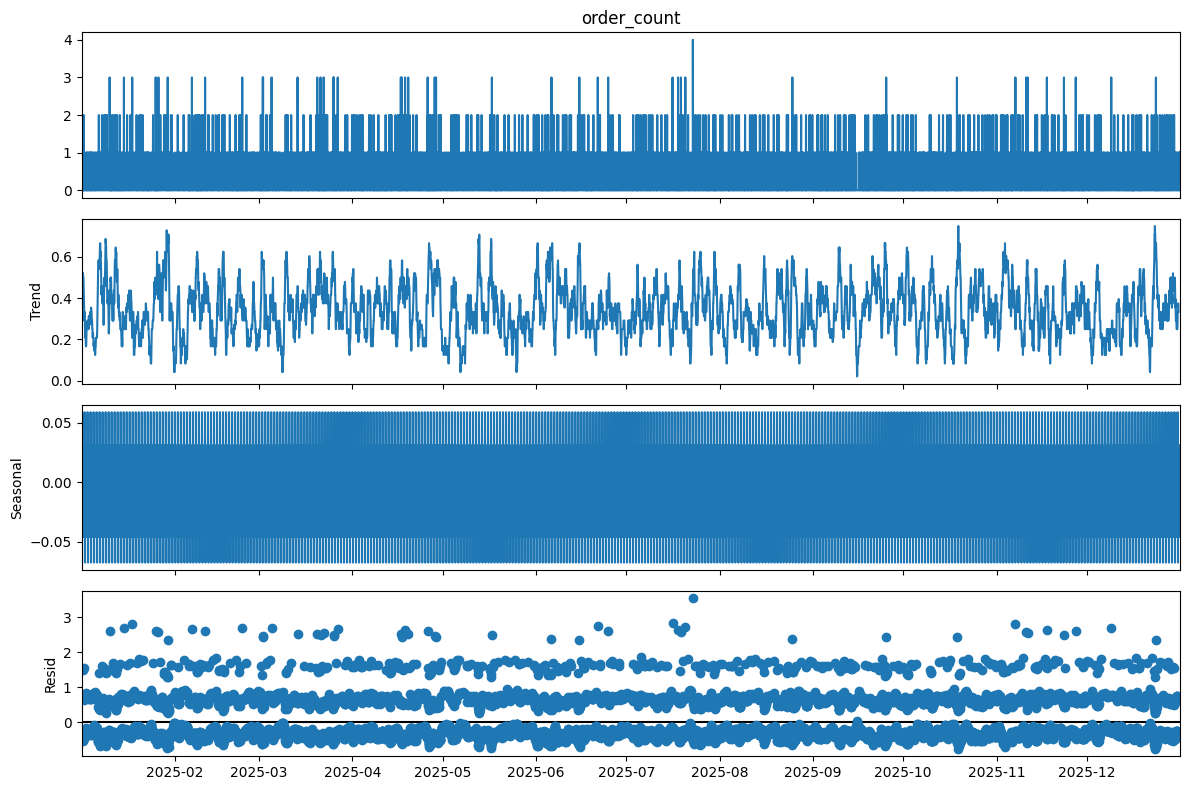

In [6]:
if len(hourly) >= 48:
    parts = seasonal_decompose(
        hourly["order_count"], model="additive", period=24
    )
    parts.plot()
    plt.gcf().set_size_inches(12, 8)
    plt.tight_layout()
    plt.savefig(PLOTS / "day5_decomposition.png", dpi=150)
    plt.show()

    decomposition_table = pd.DataFrame({
        "observed": parts.observed,
        "trend": parts.trend,
        "seasonal": parts.seasonal,
        "residual": parts.resid
    })
    decomposition_table.to_csv(OUTPUT / "day5_decomposition_components.csv")
else:
    print("Need at least 48 hourly observations for a 24-hour decomposition.")

In [7]:
# ADF null hypothesis: the series is non-stationary
def check_adf(values, name):
    result = adfuller(pd.Series(values).dropna(), autolag="AIC")
    return {
        "series": name,
        "ADF statistic": result[0],
        "p-value": result[1],
        "stationary at 5%": result[1] < 0.05
    }

adf_original = check_adf(hourly["order_count"], "Original series")
adf_difference = check_adf(hourly["order_count"].diff(), "First difference")

adf_table = pd.DataFrame([adf_original, adf_difference])
display(adf_table)
adf_table.to_csv(OUTPUT / "day5_adf_results.csv", index=False)

print("If p-value < 0.05, the ADF test provides evidence that the series is stationary.")
print("Differencing subtracts the previous hour's value from the current hour's value.")

/tmp/ipykernel_97202/1120121659.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(pd.Series(values).dropna(), autolag="AIC")
/tmp/ipykernel_97202/1120121659.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(pd.Series(values).dropna(), autolag="AIC")


,series,ADF statistic,p-value,stationary at 5%
0,Original series,-93.382831,0.0,True
1,First difference,-25.912970,0.0,True


If p-value < 0.05, the ADF test provides evidence that the series is stationary.
Differencing subtracts the previous hour's value from the current hour's value.


Training period: 2025-01-01 02:00:00 to 2025-10-19 23:00:00
Testing period: 2025-10-20 00:00:00 to 2025-12-31 22:00:00


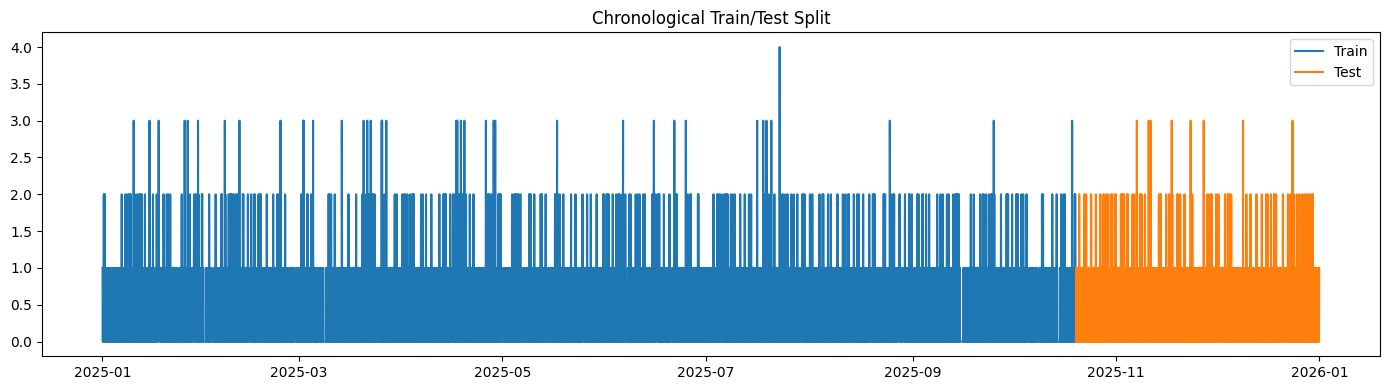

In [8]:
series = hourly["order_count"].astype(float)

test_size = max(24, int(len(series) * 0.20))
test_size = min(test_size, len(series) // 3)

if len(series) < 72:
    raise ValueError("There are too few hourly records. Use a longer timestamp range for forecasting.")

train = series.iloc[:-test_size]
test = series.iloc[-test_size:]

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

split = pd.DataFrame({
    "timestamp": series.index,
    "order_count": series.values,
    "set": ["train"] * len(train) + ["test"] * len(test)
})
split.to_csv(OUTPUT / "day5_train_test_split.csv", index=False)

plt.figure(figsize=(14, 4))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")
plt.title("Chronological Train/Test Split")
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS / "day5_train_test_split.png", dpi=150)
plt.show()

In [9]:
baseline_pred = np.repeat(train.iloc[-1], len(test))

d = 0 if adf_original["stationary at 5%"] else 1
arima_order = (1, d, 1)

arima_model = ARIMA(
    train,
    order=arima_order,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit()

arima_pred = np.clip(arima_model.forecast(steps=len(test)).to_numpy(), 0, None)
print("ARIMA order:", arima_order)
print(arima_model.summary())

ARIMA order: (1, 0, 1)
                               SARIMAX Results                                
Dep. Variable:            order_count   No. Observations:                 7006
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -6232.996
Date:                Wed, 28 Oct 2026   AIC                          12473.992
Time:                        17:15:16   BIC                          12501.408
Sample:                    01-01-2025   HQIC                         12483.439
                         - 10-19-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3444      0.011     30.247      0.000       0.322       0.367
ar.L1          0.0925      3.483      0.027      0.979      -6.734       6.919
ma.L1         -0.0909      3.

In [ ]:
try:
    from prophet import Prophet

    prophet_train = train.rename_axis("ds").reset_index()
    prophet_train.columns = ["ds", "y"]

    prophet_model = Prophet(
        daily_seasonality=True,
        weekly_seasonality=True,
        yearly_seasonality=False
    )
    prophet_model.fit(prophet_train)

    future_test = prophet_model.make_future_dataframe(
        periods=len(test), freq="h", include_history=False
    )
    prophet_pred = np.clip(
        prophet_model.predict(future_test)["yhat"].to_numpy(), 0, None
    )
    print("Prophet model completed.")
except ImportError:
    prophet_model = None
    prophet_pred = None
    print("Prophet is not installed.")

Importing plotly failed. Interactive plots will not work.
17:15:38 - cmdstanpy - INFO - Chain [1] start processing
17:15:40 - cmdstanpy - INFO - Chain [1] done processing


Prophet model completed.


In [11]:
def score_forecast(actual, predicted, name):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    # MAPE cannot be calculated where actual demand is zero
    nonzero = actual != 0
    mape = (
        np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100
        if nonzero.any() else np.nan
    )

    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%) for nonzero actuals": mape
    }

scores = [
    score_forecast(test, baseline_pred, "Naive baseline"),
    score_forecast(test, arima_pred, f"ARIMA{arima_order}")
]
if prophet_pred is not None:
    scores.append(score_forecast(test, prophet_pred, "Prophet"))

comparison = pd.DataFrame(scores).sort_values("MAE").reset_index(drop=True)
display(comparison)
comparison.to_csv(OUTPUT / "day5_model_comparison.csv", index=False)

,Model,MAE,RMSE,MAPE (%) for nonzero actuals
0,Naive baseline,0.335237,0.670416,100.000000
1,"ARIMA(1, 0, 1)",0.484906,0.580653,68.577234
2,Prophet,0.486568,0.580639,67.927566


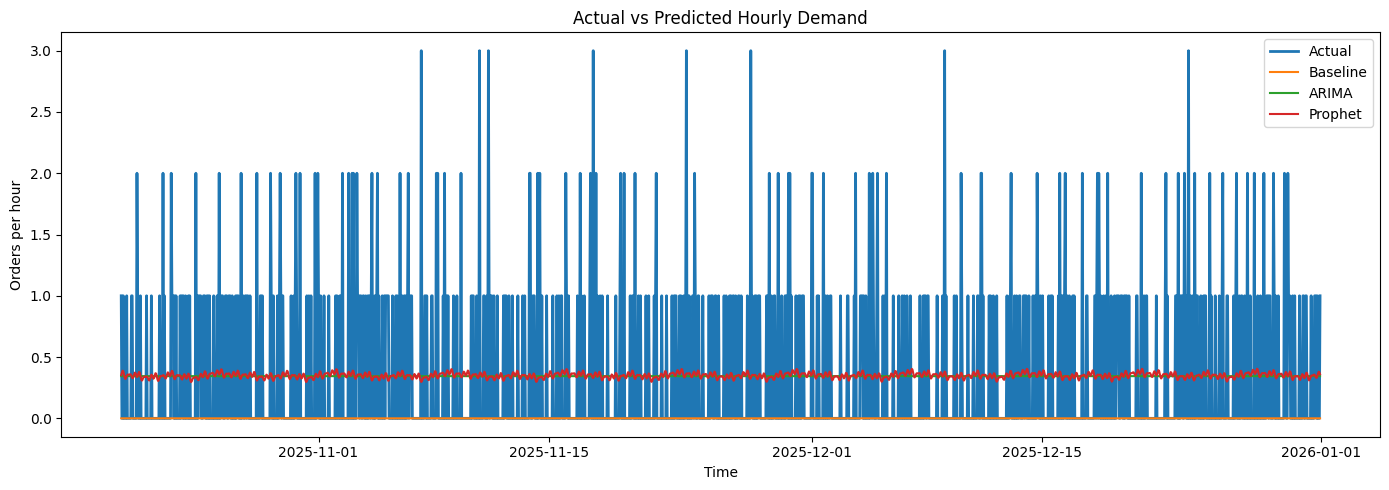

In [12]:
predictions = pd.DataFrame({
    "timestamp": test.index,
    "actual_orders": test.values,
    "baseline_prediction": baseline_pred,
    "arima_prediction": arima_pred
})
if prophet_pred is not None:
    predictions["prophet_prediction"] = prophet_pred

predictions.to_csv(OUTPUT / "day5_test_predictions.csv", index=False)

plt.figure(figsize=(14, 5))
plt.plot(test.index, test.values, label="Actual", linewidth=2)
plt.plot(test.index, baseline_pred, label="Baseline")
plt.plot(test.index, arima_pred, label="ARIMA")
if prophet_pred is not None:
    plt.plot(test.index, prophet_pred, label="Prophet")
plt.title("Actual vs Predicted Hourly Demand")
plt.xlabel("Time")
plt.ylabel("Orders per hour")
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS / "day5_actual_vs_predicted.png", dpi=150)
plt.show()

,timestamp,forecast_orders,selected_model
0,2025-12-31 23:00:00,1.0,Naive baseline
1,2026-01-01 00:00:00,1.0,Naive baseline
2,2026-01-01 01:00:00,1.0,Naive baseline
3,2026-01-01 02:00:00,1.0,Naive baseline
4,2026-01-01 03:00:00,1.0,Naive baseline
5,2026-01-01 04:00:00,1.0,Naive baseline
6,2026-01-01 05:00:00,1.0,Naive baseline
7,2026-01-01 06:00:00,1.0,Naive baseline
8,2026-01-01 07:00:00,1.0,Naive baseline
9,2026-01-01 08:00:00,1.0,Naive baseline


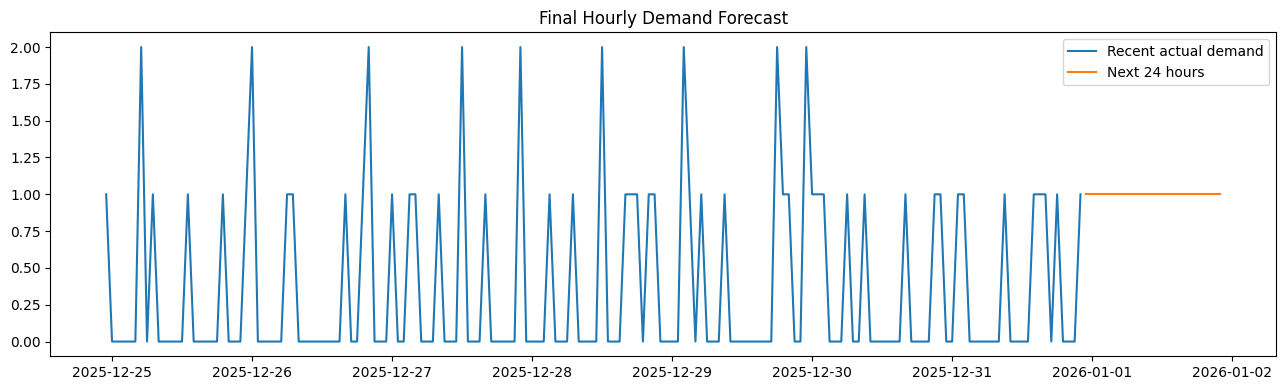

In [13]:
best_model = comparison.iloc[0]["Model"]
future_index = pd.date_range(
    series.index[-1] + pd.Timedelta(hours=1), periods=24, freq="h"
)

if best_model.startswith("ARIMA"):
    final_model = ARIMA(
        series, order=arima_order,
        enforce_stationarity=False, enforce_invertibility=False
    ).fit()
    future_values = np.clip(final_model.forecast(steps=24).to_numpy(), 0, None)

elif best_model == "Prophet" and prophet_model is not None:
    all_data = series.rename_axis("ds").reset_index()
    all_data.columns = ["ds", "y"]
    final_prophet = Prophet(daily_seasonality=True, weekly_seasonality=True,
                            yearly_seasonality=False)
    final_prophet.fit(all_data)
    future = final_prophet.make_future_dataframe(periods=24, freq="h", include_history=False)
    future_values = np.clip(final_prophet.predict(future)["yhat"].to_numpy(), 0, None)

else:
    future_values = np.repeat(series.iloc[-1], 24)

final_forecast = pd.DataFrame({
    "timestamp": future_index,
    "forecast_orders": np.round(future_values, 2),
    "selected_model": best_model
})
display(final_forecast)
final_forecast.to_csv(OUTPUT / "day5_final_demand_forecast.csv", index=False)

plt.figure(figsize=(13, 4))
recent = series.iloc[-min(len(series), 7 * 24):]
plt.plot(recent.index, recent.values, label="Recent actual demand")
plt.plot(final_forecast["timestamp"], final_forecast["forecast_orders"], label="Next 24 hours")
plt.title("Final Hourly Demand Forecast")
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS / "day5_final_forecast.png", dpi=150)
plt.show()

In [14]:
peak_hour = int(average_by_hour.idxmax())
quiet_hour = int(average_by_hour.idxmin())
best = comparison.iloc[0]

business_summary = pd.DataFrame([{
    "average_orders_per_hour": round(float(series.mean()), 2),
    "peak_hour_of_day": f"{peak_hour:02d}:00",
    "average_orders_at_peak_hour": round(float(average_by_hour.max()), 2),
    "quietest_hour_of_day": f"{quiet_hour:02d}:00",
    "average_orders_at_quietest_hour": round(float(average_by_hour.min()), 2),
    "best_model_by_test_MAE": best["Model"],
    "test_MAE": round(float(best["MAE"]), 2),
    "test_RMSE": round(float(best["RMSE"]), 2),
    "test_MAPE_percent_nonzero_actuals": round(float(best["MAPE (%) for nonzero actuals"]), 2)
}])
display(business_summary)
business_summary.to_csv(OUTPUT / "day5_business_summary.csv", index=False)

print(f"Peak average demand is at {peak_hour:02d}:00.")
print(f"Lowest average demand is at {quiet_hour:02d}:00.")
print(f"Best model by test MAE: {best['Model']}.")
print("Business use: use forecast peaks to plan driver coverage and operational capacity.")
print("Interpret the results using your actual output; do not assume a peak time before running the analysis.")

,average_orders_per_hour,peak_hour_of_day,average_orders_at_peak_hour,quietest_hour_of_day,average_orders_at_quietest_hour,best_model_by_test_MAE,test_MAE,test_RMSE,test_MAPE_percent_nonzero_actuals
0,0.34,02:00,0.4,06:00,0.28,Naive baseline,0.34,0.67,100.0


Peak average demand is at 02:00.
Lowest average demand is at 06:00.
Best model by test MAE: Naive baseline.
Business use: use forecast peaks to plan driver coverage and operational capacity.
Interpret the results using your actual output; do not assume a peak time before running the analysis.
